In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import inspect
import json
import sys
import warnings

import numpy as np
import pandas as pd
import scipy
from scipy.signal import find_peaks
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src/snr_sweep.py").is_file():
    raise RuntimeError("Save this notebook in the project notebooks/ folder.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src import snr_sweep as sweep
from src.manifests import load_manifest

MODELS = tuple(sweep.MODELS)
SNRS = tuple(sweep.SNR_LEVELS)
NOISE_SEEDS = tuple(int(x) for x in sweep.NOISE_SEEDS)
SHOW_SNRS = (20, 50)
N_BOOT = 5000
BOOT_SEED = 20261011
# Change to None for bands describing the actual held-out simulation sample.
N_TARGET = None  # Uncertainty for the actual held-out simulation sample.
FLUX_CUT, SIGMA_CUT = 0.85, 3.0
RECOVERY_FLUX = 0.85

OUT = (
    ROOT / "outputs/cos_lsf_snr/strong_absorbers"
    / f"recovery085_{datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')}"
)
HALF_WINDOW_KMS = 300.0
DEPTH_LABELS = ("0.60 <= Fmin < 0.85", "0.30 <= Fmin < 0.60", "Fmin < 0.30")
ASYM_EDGES = np.linspace(-2.0, 2.0, 81)
OUT.mkdir(parents=True, exist_ok=True)

manifest_path = ROOT / "outputs/uvb_mean_flux/manifests/z0_b15_seed42.npz"
manifest = load_manifest(manifest_path)
bundles = np.asarray(manifest["bundles"], dtype=int)
train_ids = np.sort(manifest["train_bundle_ids"].astype(int))
test_ids = np.sort(manifest["test_bundle_ids"].astype(int))
n_los = int(manifest["n_los"])
n_bundle, bundle_size = bundles.shape
n_reference = len(test_ids) * bundle_size
if set(train_ids) & set(test_ids) or set(np.r_[train_ids, test_ids]) != set(range(n_bundle)):
    raise RuntimeError("Invalid frozen bundle partition.")
if np.unique(bundles).size != bundles.size or bundles.min() < 0 or bundles.max() >= n_los:
    raise RuntimeError("Manifest contains repeated or out-of-range LOS IDs.")
los_bundle = np.full(n_los, -1, dtype=np.int32)
los_split = np.full(n_los, -1, dtype=np.int8)
los_bundle[bundles.ravel()] = np.repeat(np.arange(n_bundle), bundle_size)
los_split[bundles[train_ids].ravel()] = 0
los_split[bundles[test_ids].ravel()] = 1
used_los = np.flatnonzero(los_split >= 0)
test_position = np.full(n_bundle, -1, dtype=int)
test_position[test_ids] = np.arange(len(test_ids))
missing = [str(ROOT / "outputs/cos_lsf_snr/snr_sweep/clean_flux" / f"{m}.npz")
           for m in MODELS if not (ROOT / "outputs/cos_lsf_snr/snr_sweep/clean_flux" / f"{m}.npz").is_file()]
if missing:
    raise FileNotFoundError("Existing clean LP1 caches are required:\n" + "\n".join(missing))
if MODELS[0] != "EX0" or not set(SHOW_SNRS).issubset(SNRS):
    raise RuntimeError("Expected EX0 first and S/N 20, 50 in the sweep.")
band_scale = np.sqrt(n_reference / (n_reference if N_TARGET is None else N_TARGET))
band_scope = (f"{n_reference:,} held-out chunks" if N_TARGET is None else
              f"nominal {N_TARGET:,}-chunk scaling")
print(f"Export: {len(used_los):,} unique LOS/model; {len(SNRS)} S/N levels; {len(NOISE_SEEDS)} noise seeds.")
print(f"Figures: test split only ({n_reference:,} chunks/model). Bands: {band_scope}.")


Export: 9,990 unique LOS/model; 6 S/N levels; 3 noise seeds.
Figures: test split only (2,010 chunks/model). Bands: 2,010 held-out chunks.


In [2]:
def smooth_three(flux, sigma, *, periodic=True, valid=None):
    """Arithmetic 3-bin mean and its independent-pixel propagated error.

    For real data later: pass a common uniform velocity grid, per-bin errors,
    valid=False for masked/gap bins, and periodic=False. Rebinning covariance
    must be checked before using this independent-error propagation.
    """
    flux = np.asarray(flux, dtype=float)
    if flux.ndim != 1 or flux.size < 3:
        raise ValueError("Expected a 1D flux array with at least 3 pixels.")
    error = np.broadcast_to(np.asarray(sigma, dtype=float), flux.shape)
    good = np.isfinite(flux) & np.isfinite(error) & (error > 0)
    if valid is not None:
        good &= np.asarray(valid, dtype=bool)
    safe_flux = np.where(good, flux, 0.0)
    safe_var = np.where(good, error**2, 0.0)
    fs = (np.roll(safe_flux, 1) + safe_flux + np.roll(safe_flux, -1)) / 3
    es = np.sqrt(np.roll(safe_var, 1) + safe_var + np.roll(safe_var, -1)) / 3
    usable = np.roll(good, 1) & good & np.roll(good, -1)
    if not periodic:
        usable[[0, -1]] = False
    return fs, es, usable


def local_minima(values, usable, *, periodic):
    """One midpoint per plateau; never find peaks through NaNs or gaps."""
    if periodic:
        if not usable.all():
            raise ValueError("Periodic mock detection requires every pixel to be valid.")
        n = len(values)
        peaks, _ = find_peaks(-np.tile(values, 3))
        return peaks[(peaks >= n) & (peaks < 2*n)] - n
    # Search each continuous usable segment separately; segment endpoints are
    # not candidates because they lack two usable neighboring smoothed bins.
    edges = np.flatnonzero(np.diff(np.r_[False, usable, False]))
    candidates = []
    for start, stop in edges.reshape(-1, 2):
        peaks, _ = find_peaks(-values[start:stop])
        candidates.extend((peaks + start).tolist())
    return np.asarray(candidates, dtype=int)


def merge_minima(candidates, fs, *, periodic, usable, recovery_flux=0.85):
    """One detection per connected usable trough with F < recovery_flux.

    Return the deepest qualifying minimum and its merge multiplicity.
    F == recovery_flux separates troughs. Equal depths use pixel index.
    """
    candidates = np.asarray(candidates, dtype=int)
    fs = np.asarray(fs, dtype=float)
    below = (
        np.asarray(usable, dtype=bool)
        & np.isfinite(fs)
        & (fs < recovery_flux)
    )

    if candidates.size == 0:
        return np.empty(0, dtype=int), np.empty(0, dtype=np.int32)

    if not np.all(below[candidates]):
        raise ValueError(
            "Every candidate must lie inside a usable sub-threshold trough."
        )

    # Label contiguous troughs; zero denotes background or invalid bins.
    starts = below & ~np.r_[False, below[:-1]]
    labels = np.cumsum(starts)
    labels[~below] = 0

    # Join a trough spanning the periodic sightline boundary.
    if periodic and below[0] and below[-1]:
        last_label = labels[-1]
        labels[labels == last_label] = labels[0]

    candidate_labels = labels[candidates]
    retained, multiplicities = [], []

    for label in np.unique(candidate_labels):
        members = candidates[candidate_labels == label]
        winner = members[np.lexsort((members, fs[members]))[0]]
        retained.append(int(winner))
        multiplicities.append(len(members))

    order = np.argsort(retained)
    return (
        np.asarray(retained, dtype=int)[order],
        np.asarray(multiplicities, dtype=np.int32)[order],
    )


def detect_minima(flux, sigma, dv, *, periodic=True, valid=None):
    if not np.isfinite(dv) or dv <= 0:
        raise ValueError("dv must be positive and finite.")

    fs, es, usable = smooth_three(
        flux, sigma, periodic=periodic, valid=valid
    )
    candidates = local_minima(fs, usable, periodic=periodic)
    significance = (1.0 - fs[candidates]) / es[candidates]
    candidates = candidates[
        (fs[candidates] < FLUX_CUT)
        & (significance >= SIGMA_CUT)
    ]

    centers, n_merged = merge_minima(
        candidates,
        fs,
        periodic=periodic,
        usable=usable,
        recovery_flux=RECOVERY_FLUX,
    )
    return centers, fs, es, n_merged


def depth_bin(fmin):
    """Depth class is determined by the noisy, smoothed detection value."""
    fmin = np.asarray(fmin)
    return np.where(fmin >= 0.6, 0, np.where(fmin >= 0.3, 1, 2)).astype(np.int8)


def window_geometry(dv):
    half = int(np.floor(HALF_WINDOW_KMS / dv))
    offsets = np.arange(-half, half+1)
    velocity = offsets * dv
    lower, upper = velocity - dv/2, velocity + dv/2
    blue = np.maximum(0.0, np.minimum(upper, 0.0) - np.maximum(lower, -HALF_WINDOW_KMS))
    red = np.maximum(0.0, np.minimum(upper, HALF_WINDOW_KMS) - np.maximum(lower, 0.0))
    np.testing.assert_allclose([blue.sum(), red.sum()], HALF_WINDOW_KMS, atol=1e-10)
    return offsets, velocity, blue, red


def equivalent_widths(windows, sigma, blue_width, red_width):
    """Unclipped flux; exact +/-300 km/s support; half central bin each side.

    EW errors below assume independent pixels and a fixed selected center.
    They are denominator-stability diagnostics, not post-selection p values.
    A need not lie in [-1, 1] for noisy, unclipped profiles.
    """
    absorption = 1.0 - np.asarray(windows, dtype=float)
    eb, er = absorption @ blue_width, absorption @ red_width
    ew = eb + er
    sigma_ew = np.broadcast_to(sigma, ew.shape) * np.linalg.norm(blue_width + red_width)
    asymmetry = np.divide(er-eb, ew, out=np.full_like(ew, np.nan), where=ew > 0)
    return eb, er, ew, sigma_ew, asymmetry


def get_windows(flux, centers, offsets):
    return np.asarray(flux)[(centers[:, None] + offsets[None, :]) % len(flux)]


def json_plain(value):
    if isinstance(value, dict):
        return {str(k): json_plain(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_plain(v) for v in value]
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    return value


In [3]:
parts = []
source_metadata = {}
seed_rows, asym_rows = [], []
moments = {}
dv = None

for m, model in enumerate(MODELS):
    # This validates the existing cache against calibration and source files.
    clean_all, current_dv, metadata = sweep.cache_lp1_flux(model, ROOT)
    if clean_all.shape[0] != n_los or not np.all(np.isfinite(clean_all)):
        raise RuntimeError(f"Invalid clean cache for {model}.")
    if dv is None:
        dv = float(current_dv)
        n_pixel = clean_all.shape[1]
        path_per_los = n_pixel * dv
        offsets, velocity, blue_width, red_width = window_geometry(dv)
        n_window = len(offsets)
        if n_window != 87 or not np.isclose(path_per_los, 2500.0):
            raise RuntimeError("Expected 87-bin windows on the 2500 km/s LP1 grid.")
        shape = (len(SNRS), len(NOISE_SEEDS), len(MODELS), len(test_ids), 3)
        count = np.zeros(shape, dtype=np.int32)
        profile_sum = np.zeros(shape + (n_window,), dtype=float)
        clean_profile_sum = np.zeros_like(profile_sum)
    elif clean_all.shape[1] != n_pixel or not np.isclose(current_dv, dv, rtol=0, atol=1e-12):
        raise RuntimeError("All models must have identical grids.")
    source_metadata[model] = metadata

    for s, snr in enumerate(SNRS):
        sigma = float(sweep.sigma_per_bin(snr))
        for r, seed in enumerate(NOISE_SEEDS):
            # Preserve exact S/N sweep draws: noise on all LOS, original order.
            noisy_all = sweep.add_noise(clean_all, snr, model=model, noise_seed=seed)
            records = {key: [] for key in (
                "windows", "clean_windows_at_noisy_centers", "los_id",
                "center_pixel", "fmin", "significance", "wraps_boundary",
                "nearest_detection_kms", "n_merged",
            )}
            for los in used_los:
                centers, fs, es, n_merged = detect_minima(
                    noisy_all[los], sigma, dv
                )
                n = len(centers)
                if n == 0:
                    continue
                windows = get_windows(noisy_all[los], centers, offsets)
                clean_windows = get_windows(clean_all[los], centers, offsets)
                fmin = fs[centers]
                depths = depth_bin(fmin)
                records["windows"].append(windows.astype(np.float32))
                records["clean_windows_at_noisy_centers"].append(clean_windows.astype(np.float32))
                records["los_id"].append(np.full(n, los, dtype=np.int32))
                records["center_pixel"].append(centers.astype(np.int16))
                records["fmin"].append(fmin)
                records["n_merged"].append(n_merged)
                records["significance"].append((1-fmin) / es[centers])
                records["wraps_boundary"].append((centers+offsets[0] < 0) | (centers+offsets[-1] >= n_pixel))
                sep = np.abs(centers[:, None] - centers[None, :])
                sep = np.minimum(sep, n_pixel-sep).astype(float) * dv
                np.fill_diagonal(sep, np.inf)
                nearest = sep.min(axis=1)
                nearest[~np.isfinite(nearest)] = np.nan
                records["nearest_detection_kms"].append(nearest)
                if los_split[los] == 1:
                    b = test_position[los_bundle[los]]
                    for d in range(3):
                        selected = depths == d
                        count[s, r, m, b, d] += selected.sum()
                        profile_sum[s, r, m, b, d] += windows[selected].sum(axis=0)
                        clean_profile_sum[s, r, m, b, d] += clean_windows[selected].sum(axis=0)

            if records["windows"]:
                data = {key: np.concatenate(value) for key, value in records.items()}
            else:
                data = {"windows": np.empty((0, n_window), dtype=np.float32),
                        "clean_windows_at_noisy_centers": np.empty((0, n_window), dtype=np.float32)}
                for key, dtype in (
                    ("los_id", "i4"),
                    ("center_pixel", "i2"),
                    ("fmin", "f8"),
                    ("significance", "f8"),
                    ("wraps_boundary", "?"),
                    ("nearest_detection_kms", "f8"),
                    ("n_merged", "i4"),
                ):
                    data[key] = np.empty(0, dtype=dtype)
            n = len(data["los_id"])
            assert data["n_merged"].shape == (n,), "Merge counts must match windows."
            data.update({
                "labels": np.full(n, m, dtype=np.int8),
                "group_id": data["los_id"],
                "split": los_split[data["los_id"]],
                "bundle_id": los_bundle[data["los_id"]],
                "snr_resel": np.full(n, snr, dtype=np.int16),
                "sigma_bin": np.full(n, sigma, dtype=np.float32),
                "noise_seed": np.full(n, seed, dtype=np.int64),
                "depth_bin": depth_bin(data["fmin"]),
                "depth": 1-data["fmin"],
            })
            eb, er, ew, eew, a = equivalent_widths(data["windows"], sigma, blue_width, red_width)
            data.update({"ew_blue_kms": eb, "ew_red_kms": er, "ew_kms": ew,
                         "ew_sigma_kms": eew, "asymmetry": a,
                         "asymmetry_valid": ew > 0, "ew_ge_3sigma": ew >= 3*eew})
            parts.append(data)
            test_counts = count[s, r, m].sum(axis=0)
            for d in range(3):
                seed_rows.append({"SNR": snr, "noise_seed": seed, "model": model,
                                  "depth_bin": d, "depth_label": DEPTH_LABELS[d],
                                  "n_test_absorbers": int(test_counts[d])})
            seed_rows.append({"SNR": snr, "noise_seed": seed, "model": model,
                              "depth_bin": -1, "depth_label": "all",
                              "n_test_absorbers": int(test_counts.sum())})
            print(f"{model}, S/N {snr:2d}, seed {seed}: {n:,} windows; {int(test_counts.sum()):,} test", flush=True)
            del noisy_all, records, data
    del clean_all

catalog = {key: np.concatenate([part[key] for part in parts]) for key in parts[0]}
del parts
seed_counts = pd.DataFrame(seed_rows)
seed_counts["rate_per_1e4_kms"] = seed_counts.n_test_absorbers * 1e4 / (n_reference*path_per_los)
# Every noise realization, model and window from one LOS has one split.
np.testing.assert_array_equal(catalog["split"], los_split[catalog["los_id"]])
np.testing.assert_array_equal(catalog["bundle_id"], los_bundle[catalog["los_id"]])
for split_code in (0, 1):
    if not np.isin(catalog["los_id"][catalog["split"] == split_code],
                   bundles[train_ids if split_code == 0 else test_ids]).all():
        raise RuntimeError("Window split leakage.")
print(f"\nTotal exported examples: {len(catalog['labels']):,}; grid centres: {velocity[0]:.3f} to {velocity[-1]:.3f} km/s.")
print("EW integration uses exactly -300 to +300 km/s, including partial edge bins.")

assert np.all(catalog["n_merged"] >= 1)

merge_summary = (
    pd.DataFrame({
        "snr": catalog["snr_resel"],
        "model": np.asarray(MODELS)[catalog["labels"]],
        "n_merged": catalog["n_merged"],
    })
    .groupby(["snr", "model"], sort=True)
    .agg(
        windows=("n_merged", "size"),
        merged_windows=("n_merged", lambda x: int((x > 1).sum())),
        qualifying_minima=("n_merged", "sum"),
        largest_merge=("n_merged", "max"),
    )
)

print("Counts below include all three noise realizations.")
display(merge_summary)

n_export_candidates = int(
    np.isin(catalog["snr_resel"], [20, 50]).sum()
)
print(f"S/N 20 + 50 candidate export rows: {n_export_candidates:,}")


EX0: reused EX0.npz
EX0, S/N 10, seed 20260929: 19,266 windows; 3,829 test
EX0, S/N 10, seed 20260930: 19,464 windows; 3,877 test
EX0, S/N 10, seed 20261001: 19,297 windows; 3,806 test
EX0, S/N 15, seed 20260929: 26,408 windows; 5,217 test
EX0, S/N 15, seed 20260930: 26,616 windows; 5,321 test
EX0, S/N 15, seed 20261001: 26,325 windows; 5,257 test
EX0, S/N 20, seed 20260929: 20,999 windows; 4,159 test
EX0, S/N 20, seed 20260930: 20,998 windows; 4,195 test
EX0, S/N 20, seed 20261001: 20,957 windows; 4,133 test
EX0, S/N 30, seed 20260929: 16,583 windows; 3,269 test
EX0, S/N 30, seed 20260930: 16,523 windows; 3,302 test
EX0, S/N 30, seed 20261001: 16,549 windows; 3,249 test
EX0, S/N 50, seed 20260929: 14,849 windows; 2,947 test
EX0, S/N 50, seed 20260930: 14,795 windows; 2,955 test
EX0, S/N 50, seed 20261001: 14,829 windows; 2,942 test
EX0, S/N 80, seed 20260929: 14,235 windows; 2,823 test
EX0, S/N 80, seed 20260930: 14,202 windows; 2,830 test
EX0, S/N 80, seed 20261001: 14,244 windows; 2

windows  merged_windows  qualifying_minima  largest_merge
snr model                                                           
10  EX0      58027           19837             104525             97
    EX1      57543           19870             103754            101
    EX2      57484           20384             107288             98
    EX3      59102           19148             103733            100
15  EX0      79349           21886             127470             97
    EX1      78844           22005             126299            101
    EX2      78424           22703             129924             99
    EX3      81831           21733             129056            101
20  EX0      62954           17558             101679             97
    EX1      62341           17509             100050            100
    EX2      62556           18204             103786             98
    EX3      65570           17057             103643            100
30  EX0      49655           11894              77067             97
    EX1      49295           11966              75577             98
    EX2      49483           12578              78329             98
    EX3      51896           11694              79496            100
50  EX0      44473            7406              62608             94
    EX1      44195            7521              61112             95
    EX2      44447            7908              62439             92
    EX3      46659            7332              65272            100
80  EX0      42681            5176              55430             93
    EX1      42536            5176              54131             92
    EX2      42873            5466              54737             89
    EX3      44913            5140              58288            100

S/N 20 + 50 candidate export rows: 433,195


EX1: reused EX1.npz
EX2: reused EX2.npz
EX3: reused EX3.npz


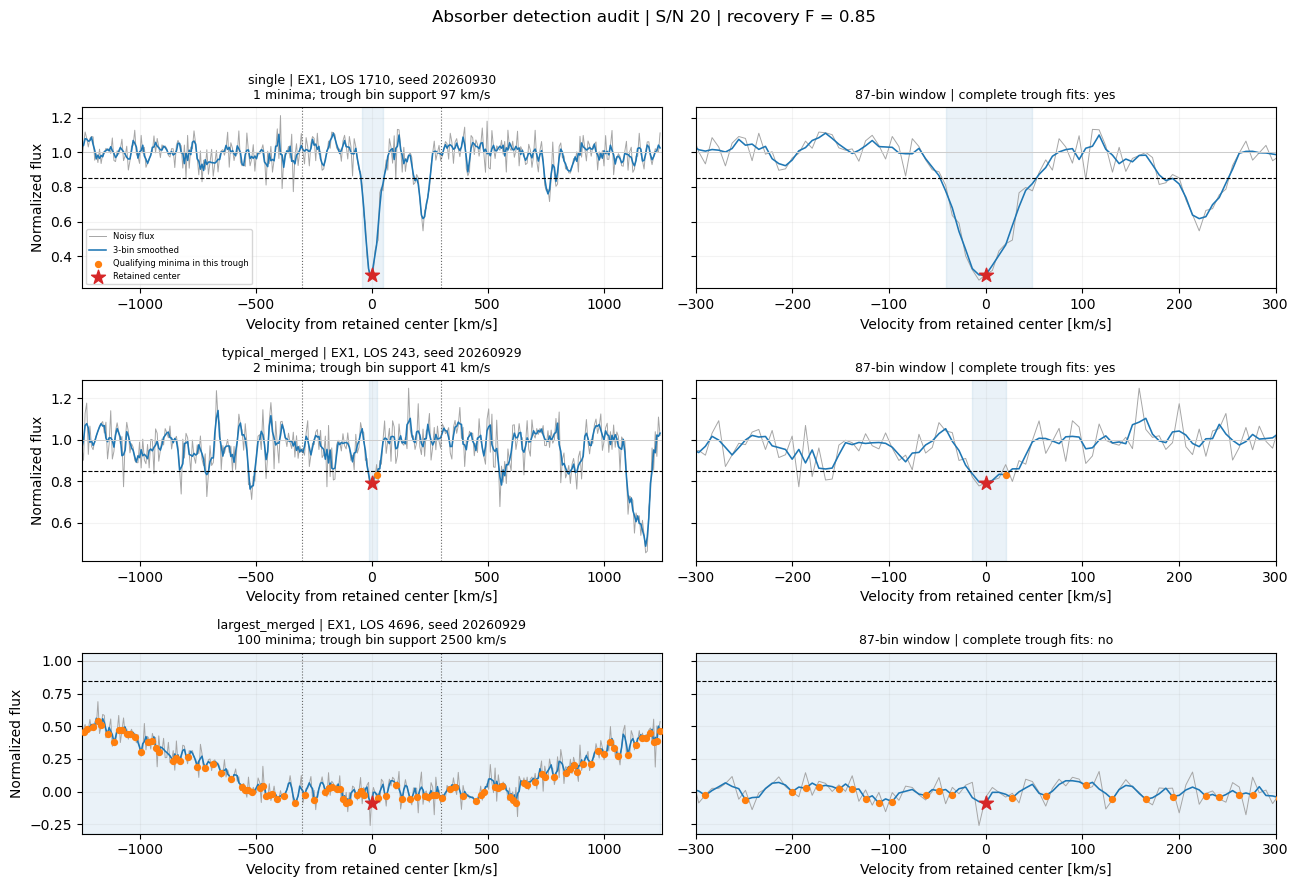

Saved: /Users/antareepgogoi/Codes/lya_forest_ml/outputs/cos_lsf_snr/strong_absorbers/recovery085_20261019T072243078016Z/window_qa/window_examples_snr20.png


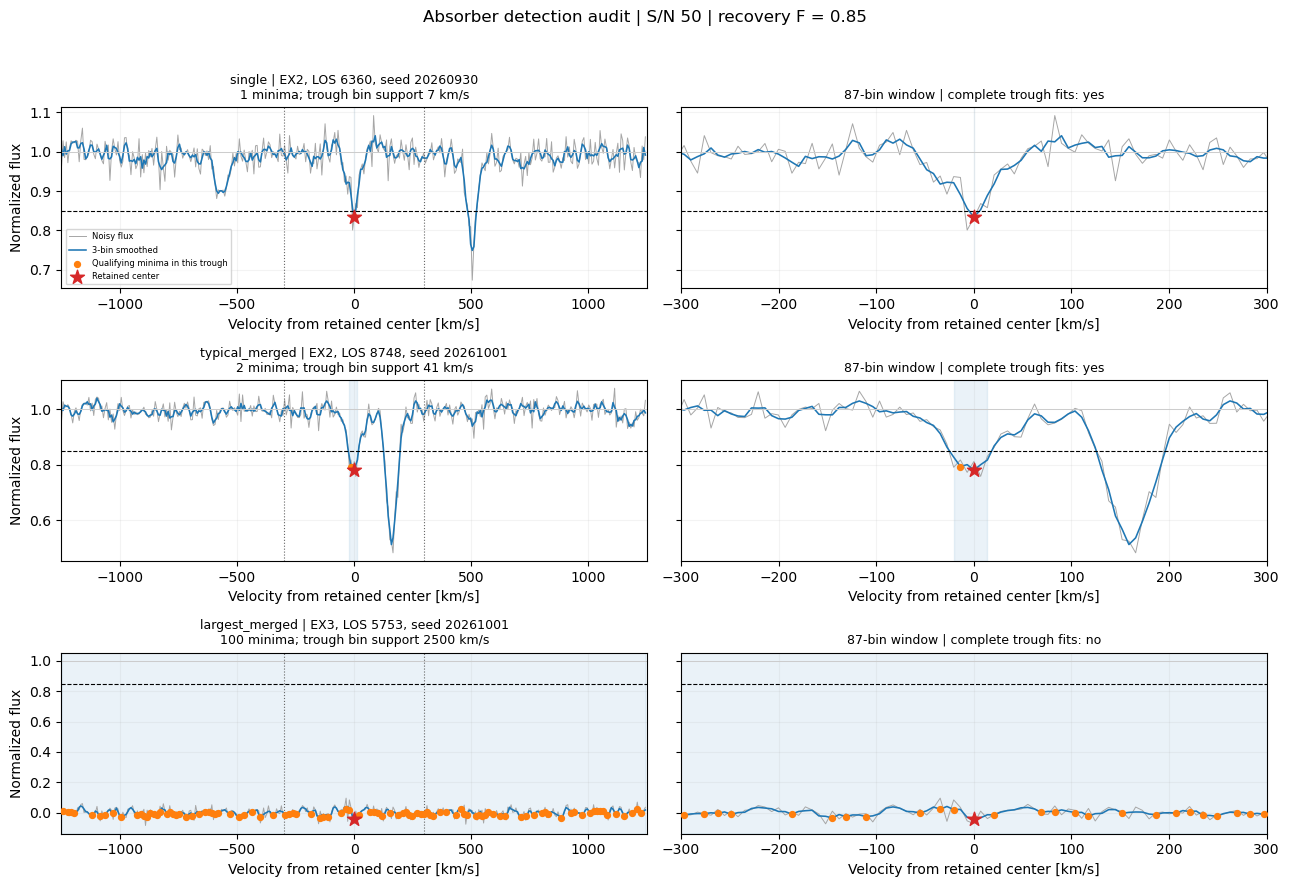

Saved: /Users/antareepgogoi/Codes/lya_forest_ml/outputs/cos_lsf_snr/strong_absorbers/recovery085_20261019T072243078016Z/window_qa/window_examples_snr50.png
All six example checks passed. These examples do not measure classifier accuracy.


,snr,case,model,los_id,n_merged,trough_bin_width_kms,trough_fits_window,whole_los_below_recovery
0,20,single,EX1,1710,1,96.69,True,False
1,20,typical_merged,EX1,243,2,41.44,True,False
2,20,largest_merged,EX1,4696,100,2500.00,False,True
3,50,single,EX2,6360,1,6.91,True,False
4,50,typical_merged,EX2,8748,2,41.44,True,False
5,50,largest_merged,EX3,5753,100,2500.00,False,True


In [4]:
qa_script = ROOT / "notebooks/sujin_window_qa_step.py"
exec(compile(
    qa_script.read_text(encoding="utf-8"), str(qa_script), "exec"
))

In [5]:
import h5py
from src import build_cos_features as cos_forward

qa_calibration = json.loads(
    (ROOT / "outputs/uvb_mean_flux/calibration/z0_b15_seed42.json").read_text()
)
qa_cases = {"EX1": [4696], "EX3": [5753]}
source_rows, source_census_rows = [], []

for qa_model in MODELS:
    qa_cache = (
        ROOT / "outputs/cos_lsf_snr/snr_sweep/clean_flux"
        / f"{qa_model}.npz"
    )
    if not qa_cache.is_file():
        raise FileNotFoundError(qa_cache)

    qa_clean, qa_dv, qa_meta = sweep.cache_lp1_flux(qa_model, ROOT)
    qa_smoothed = (
        np.roll(qa_clean, 1, axis=1)
        + qa_clean
        + np.roll(qa_clean, -1, axis=1)
    ) / 3
    qa_whole = np.all(qa_smoothed < RECOVERY_FLUX, axis=1)

    for qa_code, qa_pool in ((0, "original_train"), (1, "test")):
        qa_ids = np.flatnonzero(los_split == qa_code)
        qa_number = int(qa_whole[qa_ids].sum())
        source_census_rows.append({
            "model": qa_model,
            "pool": qa_pool,
            "n_los": len(qa_ids),
            "whole_los_below_085_clean": qa_number,
            "percent": 100 * qa_number / len(qa_ids),
        })

    for qa_los in qa_cases.get(qa_model, []):
        with h5py.File(
            ROOT / "data/raw" / f"{qa_model}_spectra.hdf5", "r"
        ) as qa_file:
            qa_tau = np.asarray(
                qa_file[qa_calibration["tau_key"]][qa_los], dtype=float
            )

        if (
            qa_tau.shape != (2499,)
            or not np.all(np.isfinite(qa_tau))
            or np.any(qa_tau < 0)
        ):
            raise RuntimeError(
                f"Invalid native optical depths: {qa_model}, LOS {qa_los}"
            )

        qa_scale = float(qa_calibration["results"][qa_model]["tau_scale"])
        with np.errstate(under="ignore"):
            qa_native = np.exp(-qa_scale * qa_tau)

        qa_rebuilt, qa_rebuilt_dv, _ = cos_forward.prepare_lp1_flux(
            qa_native[None, :],
            dv_sim=2500.0 / qa_tau.size,
            lsf_path=ROOT / cos_forward.LP1_LSF_PATH,
        )
        np.testing.assert_allclose(
            qa_rebuilt_dv, qa_dv, rtol=0, atol=1e-12
        )
        np.testing.assert_allclose(
            qa_rebuilt[0], qa_clean[qa_los], rtol=0, atol=1e-12
        )

        source_rows.append({
            "model": qa_model,
            "los_id": qa_los,
            "scaled_tau_min": float((qa_scale * qa_tau).min()),
            "scaled_tau_max": float((qa_scale * qa_tau).max()),
            "native_F_mean": float(qa_native.mean()),
            "native_F_max": float(qa_native.max()),
            "native_zero_fraction": float((qa_native == 0).mean()),
            "clean_F_max": float(qa_clean[qa_los].max()),
            "rebuild_max_abs_error": float(
                np.max(np.abs(qa_rebuilt[0] - qa_clean[qa_los]))
            ),
        })

    del qa_clean, qa_smoothed

SOURCE_AUDIT = pd.DataFrame(source_rows)
SOURCE_CENSUS = pd.DataFrame(source_census_rows)

qa_audit_dir = OUT / "window_qa"
qa_audit_dir.mkdir(parents=True, exist_ok=True)
SOURCE_AUDIT.to_csv(qa_audit_dir / "native_source_audit.csv", index=False)
SOURCE_CENSUS.to_csv(
    qa_audit_dir / "whole_los_clean_census.csv", index=False
)

display(SOURCE_AUDIT)
display(SOURCE_CENSUS.round(4))
print("Both native-to-LP1 reconstructions match the saved cache.")

EX0: reused EX0.npz
EX1: reused EX1.npz
EX2: reused EX2.npz
EX3: reused EX3.npz


,model,los_id,scaled_tau_min,scaled_tau_max,native_F_mean,native_F_max,native_zero_fraction,clean_F_max,rebuild_max_abs_error
0,EX1,4696,0.630398,1.005204e+07,0.158349,0.53238,0.083233,0.506012,0.0
1,EX3,5753,4.606149,7.519683e+07,0.000715,0.00999,0.130052,0.007320,0.0


,model,pool,n_los,whole_los_below_085_clean,percent
0,EX0,original_train,7980,10,0.1253
1,EX0,test,2010,2,0.0995
2,EX1,original_train,7980,6,0.0752
3,EX1,test,2010,2,0.0995
4,EX2,original_train,7980,6,0.0752
5,EX2,test,2010,1,0.0498
6,EX3,original_train,7980,13,0.1629
7,EX3,test,2010,4,0.1990


Both native-to-LP1 reconstructions match the saved cache.


In [6]:
rng = np.random.default_rng(BOOT_SEED)
weights = rng.multinomial(len(test_ids), np.full(len(test_ids), 1/len(test_ids)), size=N_BOOT).astype(float)


def safe_divide(num, den):
    return np.divide(num, den, out=np.full(np.broadcast_shapes(num.shape, den.shape), np.nan), where=den > 0)


def bootstrap_sum(sums):
    # sums: model, bundle, ... . The same draws apply to all models/seeds.
    flat = np.moveaxis(sums, 1, 0).reshape(len(test_ids), -1)
    return (weights @ flat).reshape((N_BOOT, len(MODELS)) + sums.shape[2:])


def percentile_bounds(center, residuals):
    """Pool within-seed residuals: seeds stabilize the mean, not sample size."""
    valid_fraction = np.isfinite(residuals).mean(axis=0)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        q = np.nanquantile(residuals, [0.025, 0.975], axis=0)
    bounds = center[None] + band_scale*q
    bounds[:, valid_fraction < 0.95] = np.nan
    return bounds, valid_fraction


def stack_bootstrap(sums, counts):
    # sums: seed, model, bundle, depth, velocity; counts lacks velocity.
    seed_mean = safe_divide(sums.sum(axis=2), counts.sum(axis=2)[..., None])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        center = np.nanmean(seed_mean, axis=0)
    residuals, delta_residuals = [], []
    for r in range(len(NOISE_SEEDS)):
        draws = safe_divide(bootstrap_sum(sums[r]), bootstrap_sum(counts[r])[..., None])
        residuals.append(draws - seed_mean[r][None])
        seed_delta = seed_mean[r] - seed_mean[r, :1]
        delta_residuals.append(draws - draws[:, :1] - seed_delta[None])
    bounds, valid_fraction = percentile_bounds(center, np.concatenate(residuals))
    delta = center - center[:1]
    delta_bounds, delta_valid = percentile_bounds(delta, np.concatenate(delta_residuals))
    return {"mean": center, "ci": bounds, "difference": delta, "difference_ci": delta_bounds,
            "valid_bootstrap_fraction": valid_fraction, "difference_valid_fraction": delta_valid}


rate_rows, contrast_rows, stack_results = [], [], {}
rate_factor = 1e4 / (n_reference * path_per_los)
for s, snr in enumerate(SNRS):
    # Separate total category plus the three mutually exclusive depth bins.
    counts4 = np.concatenate([count[s].sum(axis=-1, keepdims=True), count[s]], axis=-1)
    seed_rate = counts4.sum(axis=2) * rate_factor
    mean_rate = seed_rate.mean(axis=0)
    log_residuals, difference_residuals = [], []
    for r in range(len(NOISE_SEEDS)):
        draws = bootstrap_sum(counts4[r]) * rate_factor
        with np.errstate(divide="ignore", invalid="ignore"):
            logs = np.log(draws / seed_rate[r][None])
        logs[~np.isfinite(logs)] = np.nan
        log_residuals.append(logs)
        difference_residuals.append(draws-draws[:, :1] - (seed_rate[r]-seed_rate[r, :1])[None])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        residual_pool = np.concatenate(log_residuals)
        q = np.nanquantile(residual_pool, [0.025, 0.975], axis=0)
    rate_ci = mean_rate[None] * np.exp(band_scale*q)
    rate_ci[:, np.isfinite(residual_pool).mean(axis=0) < 0.95] = np.nan
    differences = mean_rate - mean_rate[:1]
    difference_ci, _ = percentile_bounds(differences, np.concatenate(difference_residuals))
    for m, model in enumerate(MODELS):
        for j, label in enumerate(("all",) + DEPTH_LABELS):
            rate_rows.append({"SNR": snr, "model": model, "depth_bin": j-1, "depth_label": label,
                              "rate_per_1e4_kms": mean_rate[m,j], "low": rate_ci[0,m,j], "high": rate_ci[1,m,j],
                              "seed_min": seed_rate[:,m,j].min(), "seed_max": seed_rate[:,m,j].max(),
                              "effective_Fmin_upper": min(FLUX_CUT, 1-SIGMA_CUT*sweep.sigma_per_bin(snr)/np.sqrt(3)),
                              "mean_n_test_absorbers": counts4[:,m,:,j].sum(axis=-1).mean()})
            if m > 0:
                contrast_rows.append({"SNR": snr, "model": model, "reference": "EX0", "depth_label": label,
                                      "difference_per_1e4_kms": differences[m,j],
                                      "low": difference_ci[0,m,j], "high": difference_ci[1,m,j]})
    if snr in SHOW_SNRS:
        result = stack_bootstrap(profile_sum[s], count[s])
        clean_mean = safe_divide(clean_profile_sum[s].sum(axis=2), count[s].sum(axis=2)[...,None])
        result["clean_at_noisy_centers"] = np.nanmean(clean_mean, axis=0)
        # Same selected objects and noisy centers isolate additive noise selection.
        bias_result = stack_bootstrap(profile_sum[s]-clean_profile_sum[s], count[s])
        result["selection_bias"] = bias_result["mean"]
        result["selection_bias_ci"] = bias_result["ci"]
        result["bias_difference"] = bias_result["difference"]
        result["bias_difference_ci"] = bias_result["difference_ci"]
        result["mean_counts"] = count[s].sum(axis=2).mean(axis=0)
        stack_results[snr] = result
    print(f"Bootstrap complete: S/N {snr}", flush=True)
rates = pd.DataFrame(rate_rows)
rate_contrasts = pd.DataFrame(contrast_rows)


Bootstrap complete: S/N 10
Bootstrap complete: S/N 15
Bootstrap complete: S/N 20
Bootstrap complete: S/N 30
Bootstrap complete: S/N 50
Bootstrap complete: S/N 80


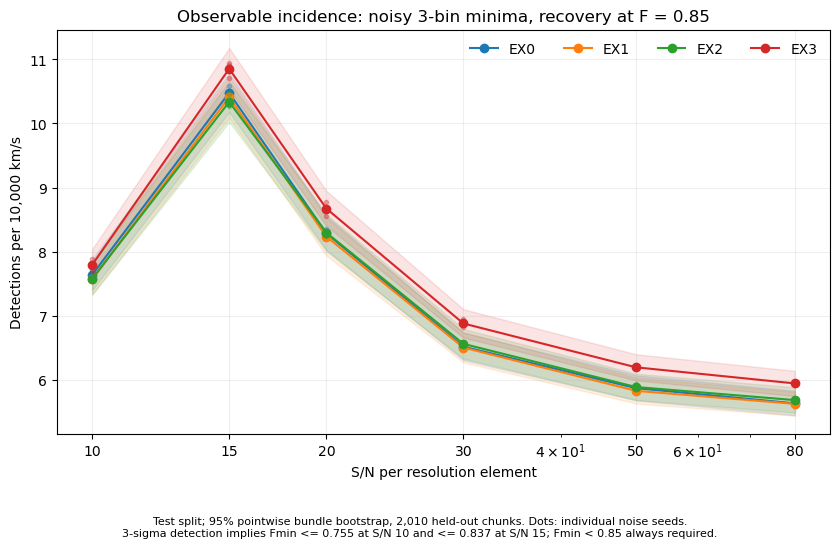

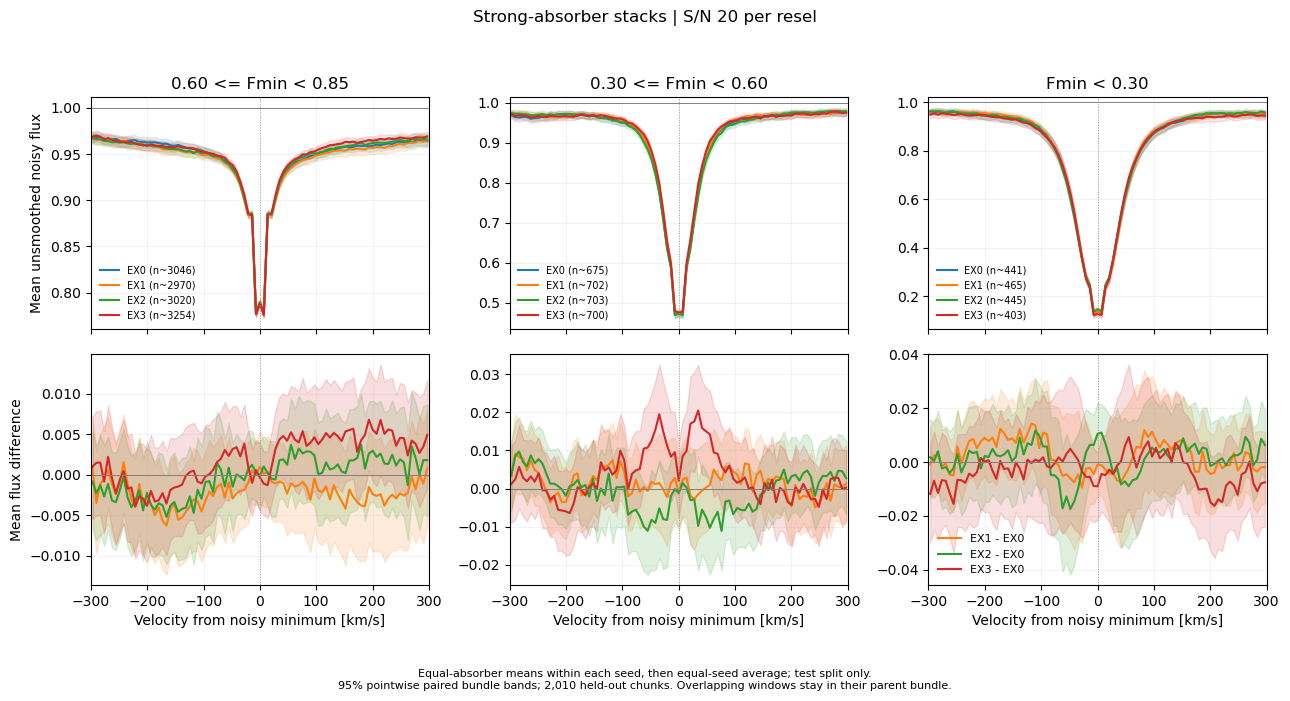

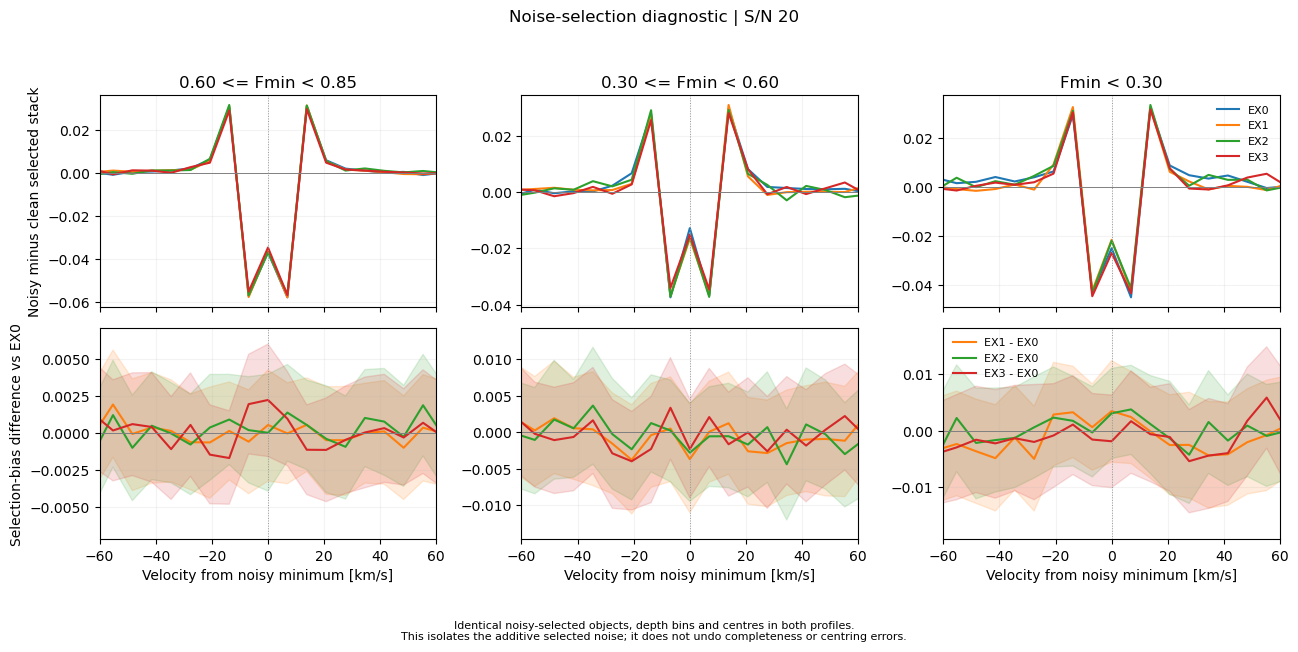

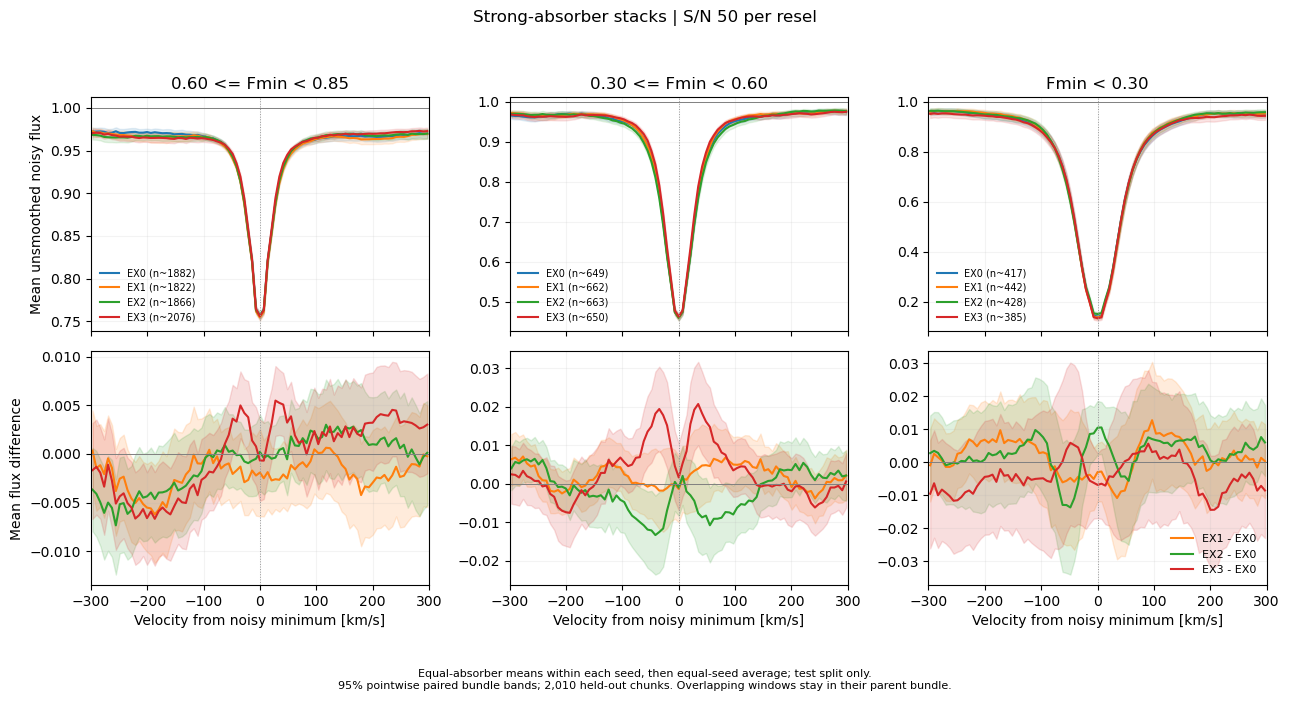

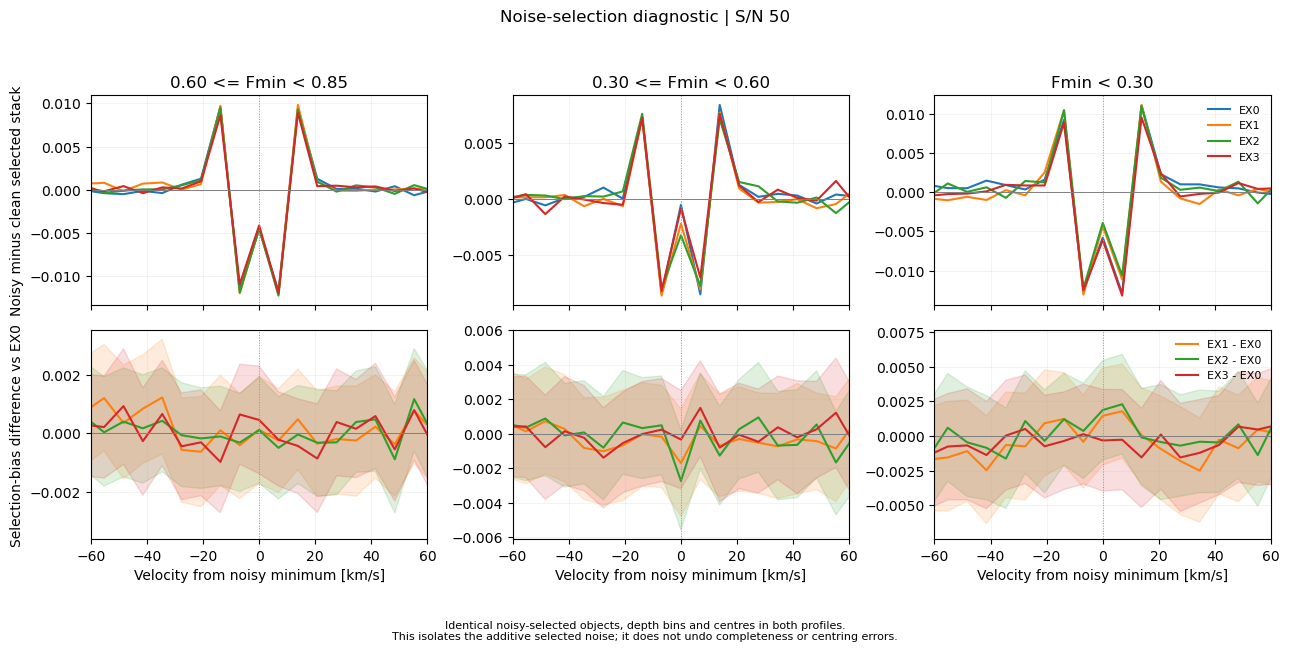

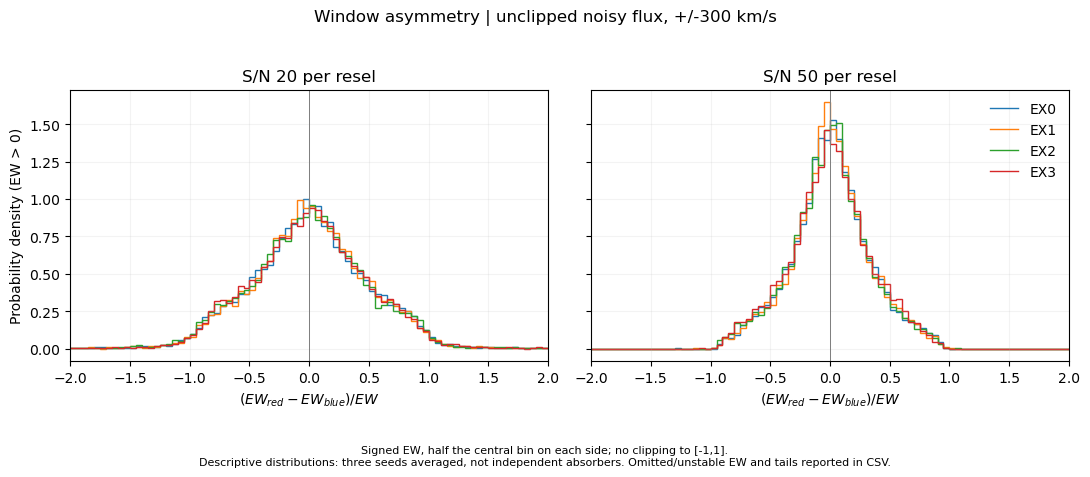

In [7]:
colors = plt.get_cmap("tab10").colors[:len(MODELS)]


def save_figure(figure, name):
    figure.savefig(OUT / f"{name}.png", dpi=180, bbox_inches="tight")
    figure.savefig(OUT / f"{name}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(figure)


fig, ax = plt.subplots(figsize=(8.5, 5.5))
for m, model in enumerate(MODELS):
    frame = rates[(rates.model == model) & (rates.depth_label == "all")].sort_values("SNR")
    x, y, low, high = (frame[key].to_numpy() for key in ("SNR", "rate_per_1e4_kms", "low", "high"))
    ax.plot(x, y, "o-", color=colors[m], label=model)
    ax.fill_between(x, low, high, color=colors[m], alpha=0.12)
    for seed in NOISE_SEEDS:
        seed_frame = seed_counts[(seed_counts.model == model) & (seed_counts.depth_label == "all") &
                                 (seed_counts.noise_seed == seed)].sort_values("SNR")
        ax.plot(seed_frame.SNR, seed_frame.rate_per_1e4_kms, ".", color=colors[m], alpha=0.35)
ax.set(xlabel="S/N per resolution element", ylabel="Detections per 10,000 km/s", xscale="log",
       title="Observable incidence: noisy 3-bin minima, recovery at F = 0.85")
ax.set_xticks(SNRS, labels=[str(x) for x in SNRS])
ax.grid(alpha=0.2)
ax.legend(frameon=False, ncol=4)
fig.text(0.5, 0.015, f"Test split; 95% pointwise bundle bootstrap, {band_scope}. Dots: individual noise seeds.\n"
         "3-sigma detection implies Fmin <= 0.755 at S/N 10 and <= 0.837 at S/N 15; Fmin < 0.85 always required.",
         ha="center", fontsize=8)
fig.tight_layout(rect=(0,0.09,1,1))
save_figure(fig, "observable_incidence")

stack_rows = []
for snr in SHOW_SNRS:
    result = stack_results[snr]
    fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
    for d, label in enumerate(DEPTH_LABELS):
        axes[0,d].set_title(label)
        for m, model in enumerate(MODELS):
            y, ci = result["mean"][m,d], result["ci"][:,m,d]
            axes[0,d].plot(velocity, y, color=colors[m], label=f"{model} (n~{result['mean_counts'][m,d]:.0f})")
            axes[0,d].fill_between(velocity, ci[0], ci[1], color=colors[m], alpha=0.12)
            if m > 0:
                delta, dci = result["difference"][m,d], result["difference_ci"][:,m,d]
                axes[1,d].plot(velocity, delta, color=colors[m], label=f"{model} - EX0")
                axes[1,d].fill_between(velocity, dci[0], dci[1], color=colors[m], alpha=0.15)
            stack_rows.append(pd.DataFrame({"SNR": snr, "model": model, "depth_bin": d,
                                           "velocity_kms": velocity, "mean_flux": y, "low": ci[0], "high": ci[1],
                                           "difference_vs_EX0": result["difference"][m,d],
                                           "difference_low": result["difference_ci"][0,m,d],
                                           "difference_high": result["difference_ci"][1,m,d],
                                           "clean_at_noisy_centers": result["clean_at_noisy_centers"][m,d],
                                           "noise_selection_bias": result["selection_bias"][m,d],
                                           "bias_difference_vs_EX0": result["bias_difference"][m,d]}))
        axes[0,d].axhline(1, color="0.5", lw=0.7)
        axes[1,d].axhline(0, color="0.5", lw=0.7)
        axes[1,d].set_xlabel("Velocity from noisy minimum [km/s]")
        axes[0,d].legend(fontsize=7, frameon=False)
    axes[0,0].set_ylabel("Mean unsmoothed noisy flux")
    axes[1,0].set_ylabel("Mean flux difference")
    for ax in axes.flat:
        ax.axvline(0, color="0.6", lw=0.7, ls=":")
        ax.set_xlim(-300,300)
        ax.grid(alpha=0.15)
    axes[1,2].legend(fontsize=8, frameon=False)
    fig.suptitle(f"Strong-absorber stacks | S/N {snr} per resel")
    fig.text(0.5,0.01, f"Equal-absorber means within each seed, then equal-seed average; test split only.\n"
             f"95% pointwise paired bundle bands; {band_scope}. Overlapping windows stay in their parent bundle.",
             ha="center", fontsize=8)
    fig.tight_layout(rect=(0,0.075,1,0.95))
    save_figure(fig, f"stack_profiles_snr{snr}")

    fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
    for d, label in enumerate(DEPTH_LABELS):
        axes[0,d].set_title(label)
        for m, model in enumerate(MODELS):
            axes[0,d].plot(velocity, result["selection_bias"][m,d], color=colors[m], label=model)
            if m > 0:
                y = result["bias_difference"][m,d]
                ci = result["bias_difference_ci"][:,m,d]
                axes[1,d].plot(velocity, y, color=colors[m], label=f"{model} - EX0")
                axes[1,d].fill_between(velocity, ci[0], ci[1], color=colors[m], alpha=0.15)
        for ax in axes[:,d]:
            ax.axhline(0,color="0.5",lw=0.7)
            ax.axvline(0,color="0.6",lw=0.7,ls=":")
            ax.set_xlim(-60,60)
            ax.grid(alpha=0.15)
        axes[1,d].set_xlabel("Velocity from noisy minimum [km/s]")
    axes[0,0].set_ylabel("Noisy minus clean selected stack")
    axes[1,0].set_ylabel("Selection-bias difference vs EX0")
    axes[0,2].legend(frameon=False,fontsize=8)
    axes[1,2].legend(frameon=False,fontsize=8)
    fig.suptitle(f"Noise-selection diagnostic | S/N {snr}")
    fig.text(0.5,0.01,"Identical noisy-selected objects, depth bins and centres in both profiles.\n"
             "This isolates the additive selected noise; it does not undo completeness or centring errors.",
             ha="center",fontsize=8)
    fig.tight_layout(rect=(0,0.075,1,0.95))
    save_figure(fig,f"selection_bias_snr{snr}")

fig, axes = plt.subplots(1, len(SHOW_SNRS), figsize=(11,4.7), sharey=True, squeeze=False)
test_mask = catalog["split"] == 1
for s, snr in enumerate(SNRS):
    for m, model in enumerate(MODELS):
        histogram_seeds = []
        for seed in NOISE_SEEDS:
            select = test_mask & (catalog["snr_resel"] == snr) & (catalog["labels"] == m) & (catalog["noise_seed"] == seed)
            values = catalog["asymmetry"][select]
            finite = np.isfinite(values)
            positive = values[finite]
            reliable = catalog["ew_ge_3sigma"][select] & finite
            stable = values[reliable]
            hist = np.histogram(positive, ASYM_EDGES)[0]
            histogram_seeds.append(hist / (max(len(positive),1)*np.diff(ASYM_EDGES)))
            asym_rows.append({"SNR":snr,"model":model,"noise_seed":seed,"n_test_absorbers":int(select.sum()),
                              "n_EW_positive":int(finite.sum()),"n_EW_ge_3sigma":int(reliable.sum()),
                              "nonpositive_EW_fraction":float(1-finite.mean()) if finite.size else np.nan,
                              "outside_plot_fraction":float(np.mean((positive<ASYM_EDGES[0]) | (positive>ASYM_EDGES[-1]))) if positive.size else np.nan,
                              "median_A":float(np.median(positive)) if positive.size else np.nan,
                              "median_abs_A":float(np.median(np.abs(positive))) if positive.size else np.nan,
                              "median_abs_A_EW_ge_3sigma":float(np.median(np.abs(stable))) if stable.size else np.nan})
        if snr in SHOW_SNRS:
            ax = axes[0, SHOW_SNRS.index(snr)]
            ax.stairs(np.mean(histogram_seeds,axis=0),ASYM_EDGES,baseline=None,color=colors[m],label=model)
            ax.set(title=f"S/N {snr} per resel", xlabel=r"$(EW_{red}-EW_{blue})/EW$",xlim=(-2,2))
            ax.axvline(0,color="0.5",lw=0.7)
            ax.grid(alpha=0.15)
axes[0,0].set_ylabel("Probability density (EW > 0)")
axes[0,-1].legend(frameon=False)
fig.suptitle("Window asymmetry | unclipped noisy flux, +/-300 km/s")
fig.text(0.5,0.01,"Signed EW, half the central bin on each side; no clipping to [-1,1].\n"
         "Descriptive distributions: three seeds averaged, not independent absorbers. Omitted/unstable EW and tails reported in CSV.",
         ha="center",fontsize=8)
fig.tight_layout(rect=(0,0.10,1,0.95))
save_figure(fig,"asymmetry_distributions")
asymmetry_summary = pd.DataFrame(asym_rows)


In [8]:
export_script = ROOT / "notebooks/sujin_export_step.py"
exec(compile(export_script.read_text(encoding="utf-8"), str(export_script), "exec"))

Preparing 433,195 windows; verifying source flux and adding trough flags...
EX0: reused EX0.npz
Verified both S/N levels and all three seeds: EX0
EX1: reused EX1.npz
Verified both S/N levels and all three seeds: EX1
EX2: reused EX2.npz
Verified both S/N levels and all three seeds: EX2
EX3: reused EX3.npz
Verified both S/N levels and all three seeds: EX3
Writing compact archive...

Saved: /Users/antareepgogoi/Codes/lya_forest_ml/outputs/cos_lsf_snr/strong_absorbers/recovery085_20261019T072243078016Z/sujin_snr20_50/sujin_strong_absorber_windows_snr20_50.npz
Size: 106.9 MB (102.0 MiB); windows: 433,195
Validation: exactly the saved 798 tuning LOS; parent-role overlaps: 0.
Readback verification: all saved arrays passed. Saturated windows retained.
Briefing: /Users/antareepgogoi/Codes/lya_forest_ml/outputs/cos_lsf_snr/strong_absorbers/recovery085_20261019T072243078016Z/sujin_snr20_50/SUJIN_BRIEF.md
Window counts by S/N, role and model (three seeds combined):


model,snr,role,EX0,EX1,EX2,EX3,total
0,20,train,40171,39608,39711,41921,161411
1,20,validation,5049,4984,4930,5126,20089
2,20,calibration,5247,5337,5412,5452,21448
3,20,test,12487,12412,12503,13071,50473
4,50,train,28225,28038,28212,29663,114138
5,50,validation,3638,3555,3519,3718,14430
6,50,calibration,3766,3821,3846,3944,15377
7,50,test,8844,8781,8870,9334,35829


,snr,n_windows,n_whole_los_windows,n_troughs_outside_window
0,20,253421,99,660
1,50,179774,121,742


In [9]:
baseline_script = ROOT / "notebooks/sujin_depth_baseline_step.py"
exec(compile(
    baseline_script.read_text(encoding="utf-8"),
    str(baseline_script),
    "exec",
))

S/N 20: fitting on 161,411 windows; selecting with 20,089 validation windows...
S/N 50: fitting on 114,138 windows; selecting with 14,430 validation windows...

Saved: /Users/antareepgogoi/Codes/lya_forest_ml/outputs/cos_lsf_snr/strong_absorbers/recovery085_20261019T072243078016Z/sujin_depth_baseline_v1
Four-class depth-only results (%); balanced chance/control = 25%:


,snr,selected_max_depth,test_ba_pct,ba_ci95_low_pct,ba_ci95_high_pct,ba_seed_sd_pp,test_accuracy_pct
0,20,4,25.704,25.359,26.064,0.054,25.976
1,50,2,26.343,25.916,26.777,0.202,26.928


,snr,noise_seed,n_test_windows,test_ba_pct,ba_ci95_low_pct,ba_ci95_high_pct,test_accuracy_pct,recall_EX0_pct,recall_EX1_pct,recall_EX2_pct,recall_EX3_pct
0,20,20260929,16832,25.642,25.126,26.162,25.927,27.242,10.382,17.213,47.731
1,20,20260930,16822,25.737,25.196,26.296,25.930,26.675,10.722,17.611,47.942
2,20,20261001,16819,25.733,25.202,26.272,26.072,26.567,11.355,17.894,47.118
3,50,20260929,11956,26.170,25.731,26.624,26.681,0.000,21.044,14.732,68.905
4,50,20260930,11913,26.566,26.126,27.018,27.147,0.000,21.436,15.652,69.176
5,50,20261001,11960,26.294,25.840,26.764,26.957,0.000,20.933,15.147,69.096


In [7]:
display(
    rate_contrasts.query(
        "model == 'EX3' and depth_label == 'all'"
    ).round(4)
)

,SNR,model,reference,depth_label,difference_per_1e4_kms,low,high
8,10,EX3,EX0,all,0.0915,-0.4166,0.6184
20,15,EX3,EX0,all,0.2481,-0.2761,0.7883
32,20,EX3,EX0,all,0.2872,-0.1835,0.7686
44,30,EX3,EX0,all,0.3516,-0.1004,0.8196
56,50,EX3,EX0,all,0.3569,-0.0924,0.8142
68,80,EX3,EX0,all,0.3748,-0.0397,0.8027


with np.load(OUT / "sujin_strong_absorber_windows.npz", allow_pickle=False) as data:
    X = data["windows"]
    y = data["labels"]
    train = data["split"] == 0
    test = data["split"] == 1
    groups = data["group_id"]
    snr = data["snr_resel"]